## Задание 1 Приложение

#### Решения


- **Deployment** — приложение не хранит ничего на диске, а Deployment умеет обновлять без простоя, хранит историю и делает откат.
- **Сертификат** выпустила сама через openssl, как в семинаре 4. Он лежит в Secret типа `kubernetes.io/tls`, в репозиторий не попадает. В сертификат добавила `*.localtest.me`, чтобы он подошёл и для второго адреса в задании 4.
- **Ingress** — единственный вход снаружи: `/api` идёт в backend, всё остальное во frontend. Сервисы типа ClusterIP, поэтому напрямую к backend снаружи не подключиться.
- **Порт backend** (9090) задаю переменной `PORT` через ConfigMap: приложение читает её при старте, поэтому пересобирать образ не нужно.
- **Пробы.** Readiness убирает неготовый под из балансировки, liveness перезапускает зависший. Отдельного health-эндпоинта в приложении нет, поэтому проверяю `/api/counter` у backend и `/` у frontend.
- **Ресурсы.** Requests нужны планировщику, лимит памяти не даёт контейнеру съесть всю ноду. LimitRange подставляет лимит тем контейнерам, где его забыли указать.
- **Выкатка.** RollingUpdate с `maxSurge: 1, maxUnavailable: 0`: старая версия работает, пока новая не готова. `preStop: sleep 5` даёт ingress время убрать под из балансировки. В аннотации `change-cause` пишу, что и почему поменяла.
- **Образы** собираю на VPS и загружаю в ноды через `kind load docker-image`, потому что реестра нет. Тег 1.1.0 — та же сборка под новым тегом, чтобы показать выкатку новой версии.

#### Сборка образов

In [1]:
%%bash
ssh devopshw << 'EOF'
kubectl config current-context
kubectl get nodes -o wide
kubectl get pods -n ingress-nginx
EOF

Pseudo-terminal will not be allocated because stdin is not a terminal.


kind-course
NAME                   STATUS   ROLES           AGE     VERSION   INTERNAL-IP   EXTERNAL-IP   OS-IMAGE                       KERNEL-VERSION             CONTAINER-RUNTIME
course-control-plane   Ready    control-plane   4h35m   v1.37.0   172.19.0.4    <none>        Debian GNU/Linux 13 (trixie)   7.0.0-38-generic (amd64)   containerd://2.3.4
course-worker          Ready    <none>          4h35m   v1.37.0   172.19.0.2    <none>        Debian GNU/Linux 13 (trixie)   7.0.0-38-generic (amd64)   containerd://2.3.4
course-worker2         Ready    <none>          4h35m   v1.37.0   172.19.0.3    <none>        Debian GNU/Linux 13 (trixie)   7.0.0-38-generic (amd64)   containerd://2.3.4
NAME                                        READY   STATUS      RESTARTS        AGE
ingress-nginx-admission-create-5dcc5        0/1     Completed   0               4h34m
ingress-nginx-admission-patch-q522g         0/1     Completed   1 (4h33m ago)   4h34m
ingress-nginx-controller-7c467b649f-xb976   1/1  

In [3]:
%%bash
ssh devopshw << 'EOF'
cd ~/projects/hw4_work
docker build -q -t counter-backend:1.0.0 app/counter-backend
docker build -q -t counter-frontend:1.0.0 app/counter-frontend
docker tag counter-frontend:1.0.0 counter-frontend:1.1.0
docker images | grep counter
kind load docker-image counter-backend:1.0.0 counter-frontend:1.0.0 counter-frontend:1.1.0 --name course
docker exec course-worker crictl images | grep counter
EOF

Pseudo-terminal will not be allocated because stdin is not a terminal.
DEPRECATED: The legacy builder is deprecated and will be removed in a future release.
            Install the buildx component to build images with BuildKit:
            https://docs.docker.com/go/buildx/



sha256:5a35f2619b5ccc695d5147f24fc2fdaf9ce0d6ec14d958b46d45f917c21f26cb


DEPRECATED: The legacy builder is deprecated and will be removed in a future release.
            Install the buildx component to build images with BuildKit:
            https://docs.docker.com/go/buildx/



sha256:cf1114ef43f607badf96062cbbee720c80e7b4573c89d0b3a85cd7b047123391


counter-backend:1.0.0                                                                  5a35f2619b5c        234MB         57.8MB        
counter-backend:multistage                                                             62b41a779ba3        234MB         58.8MB   U    
counter-backend:nonroot                                                                48334dbf5ec3        234MB         58.8MB   U    
counter-backend:single                                                                 2b740e63dfa4        380MB         95.6MB   U    
counter-frontend:1.0.0                                                                 cf1114ef43f6        420MB          104MB        
counter-frontend:1.1.0                                                                 cf1114ef43f6        420MB          104MB        


Image: "counter-backend:1.0.0" with ID "sha256:5a35f2619b5ccc695d5147f24fc2fdaf9ce0d6ec14d958b46d45f917c21f26cb" not yet present on node "course-control-plane", loading...
Image: "counter-backend:1.0.0" with ID "sha256:5a35f2619b5ccc695d5147f24fc2fdaf9ce0d6ec14d958b46d45f917c21f26cb" not yet present on node "course-worker", loading...
Image: "counter-backend:1.0.0" with ID "sha256:5a35f2619b5ccc695d5147f24fc2fdaf9ce0d6ec14d958b46d45f917c21f26cb" not yet present on node "course-worker2", loading...
Image: "counter-frontend:1.0.0" with ID "sha256:cf1114ef43f607badf96062cbbee720c80e7b4573c89d0b3a85cd7b047123391" not yet present on node "course-control-plane", loading...
Image: "counter-frontend:1.0.0" with ID "sha256:cf1114ef43f607badf96062cbbee720c80e7b4573c89d0b3a85cd7b047123391" not yet present on node "course-worker", loading...
Image: "counter-frontend:1.0.0" with ID "sha256:cf1114ef43f607badf96062cbbee720c80e7b4573c89d0b3a85cd7b047123391" not yet present on node "course-worker2", lo

docker.io/library/counter-backend                    1.0.0                f5a46ee7f7716       57.8MB
docker.io/library/counter-frontend                   1.0.0                b482e8e0601e0       104MB
docker.io/library/counter-frontend                   1.1.0                b482e8e0601e0       104MB


#### Сертификат и выкатка

In [4]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
mkdir -p certs
openssl req -x509 -newkey rsa:2048 -sha256 -days 365 -nodes \
  -keyout certs/tls.key -out certs/tls.crt \
  -subj "/CN=counter.localtest.me" \
  -addext "subjectAltName=DNS:counter.localtest.me,DNS:*.localtest.me"
kubectl apply -f k8s/namespace.yaml
kubectl config set-context --current --namespace=counter
kubectl create secret tls counter-tls --cert=certs/tls.crt --key=certs/tls.key
kubectl apply -f k8s/backend.yaml -f k8s/frontend.yaml -f k8s/ingress.yaml
kubectl rollout status deployment/counter-backend
kubectl rollout status deployment/counter-frontend
EOF

....+++++++++++++++++++++++++++++++++++++++*...+.+......+.....+...+.+.........+......+..+...+++++++++++++++++++++++++++++++++++++++*......+..........+.....+.+..+.......+...........+...+......+....+.....+......+.+............+.....+......+.+..............+......+..........+........+......+....+..+.+........+.+.....++++++
....+.+...............+.....+.......+..+...+.......+......+.....+....+++++++++++++++++++++++++++++++++++++++*......+........+++++++++++++++++++++++++++++++++++++++*........+.+......+...........+...++++++
-----


namespace/counter created
limitrange/defaults created
Context "kind-course" modified.
secret/counter-tls created
configmap/counter-backend-config created
deployment.apps/counter-backend created
service/counter-backend created
deployment.apps/counter-frontend created
service/counter-frontend created
ingress.networking.k8s.io/counter created
Waiting for deployment "counter-backend" rollout to finish: 0 of 1 updated replicas are available...
deployment "counter-backend" successfully rolled out
deployment "counter-frontend" successfully rolled out


#### Проверка HTTPS 1.1

In [6]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl get deploy,pod,svc,ingress -o wide
curl -sS https://counter.localtest.me/api/counter; echo
curl -v --cacert certs/tls.crt -o /dev/null https://counter.localtest.me/
curl -sS --cacert certs/tls.crt https://counter.localtest.me/api/counter; echo
curl -sS --cacert certs/tls.crt -X POST https://counter.localtest.me/api/counter; echo
curl -sS --cacert certs/tls.crt -X POST https://counter.localtest.me/api/counter; echo
curl -sS --cacert certs/tls.crt https://counter.localtest.me/api/counter; echo
EOF

NAME                               READY   UP-TO-DATE   AVAILABLE   AGE   CONTAINERS   IMAGES                   SELECTOR
deployment.apps/counter-backend    1/1     1            1           16m   backend      counter-backend:1.0.0    app=counter-backend
deployment.apps/counter-frontend   1/1     1            1           16m   frontend     counter-frontend:1.0.0   app=counter-frontend

NAME                                    READY   STATUS    RESTARTS   AGE   IP           NODE            NOMINATED NODE   READINESS GATES
pod/counter-backend-d7d7db7d9-6cpnf     1/1     Running   0          16m   10.244.2.3   course-worker   <none>           <none>
pod/counter-frontend-79f7678d84-9xhlb   1/1     Running   0          16m   10.244.2.4   course-worker   <none>           <none>

NAME                       TYPE        CLUSTER-IP     EXTERNAL-IP   PORT(S)   AGE   SELECTOR
service/counter-backend    ClusterIP   10.96.11.211   <none>        80/TCP    16m   app=counter-backend
service/counter-fronte

curl: (60) SSL certificate OpenSSL verify result: self-signed certificate (18)
More details here: https://curl.se/docs/sslcerts.html

curl failed to verify the legitimacy of the server and therefore could not
establish a secure connection to it. To learn more about this situation and
how to fix it, please visit the webpage mentioned above.


  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed
  0      0   0      0   0      0      0      0                              0* Host counter.localtest.me:443 was resolved.
* IPv6: ::1
* IPv4: 127.0.0.1
*   Trying [::1]:443...
* connect to ::1 port 443 from ::1 port 46958 failed: Connection refused
*   Trying 127.0.0.1:443...
* ALPN: curl offers h2,http/1.1
} [5 bytes data]
* TLSv1.3 (OUT), TLS handshake, Client hello (1):
} [1575 bytes data]
* SSL Trust Anchors:
*   CAfile: certs/tls.crt
*   CApath: /etc/ssl/certs
{ [5 bytes data]
* TLSv1.3 (IN), TLS handshake, Server hello (2):
{ [122 bytes data]
* TLSv1.3 (IN), TLS change cipher, Change cipher spec (1):
{ [1 bytes data]
* TLSv1.3 (IN), TLS handshake, Encrypted Extensions (8):
{ [19 bytes data]
* TLSv1.3 (IN), TLS handshake, Certificate (11):
{ [867 bytes data]
* TLSv1.3 (IN), TLS handshake, CERT verify (15):
{ [264 bytes data]
*

{"count": 1}
{"count": 2}
{"count": 3}
{"count": 3}


#### каунт начианется не с 0, т.к. на странице уже нажала инкремент

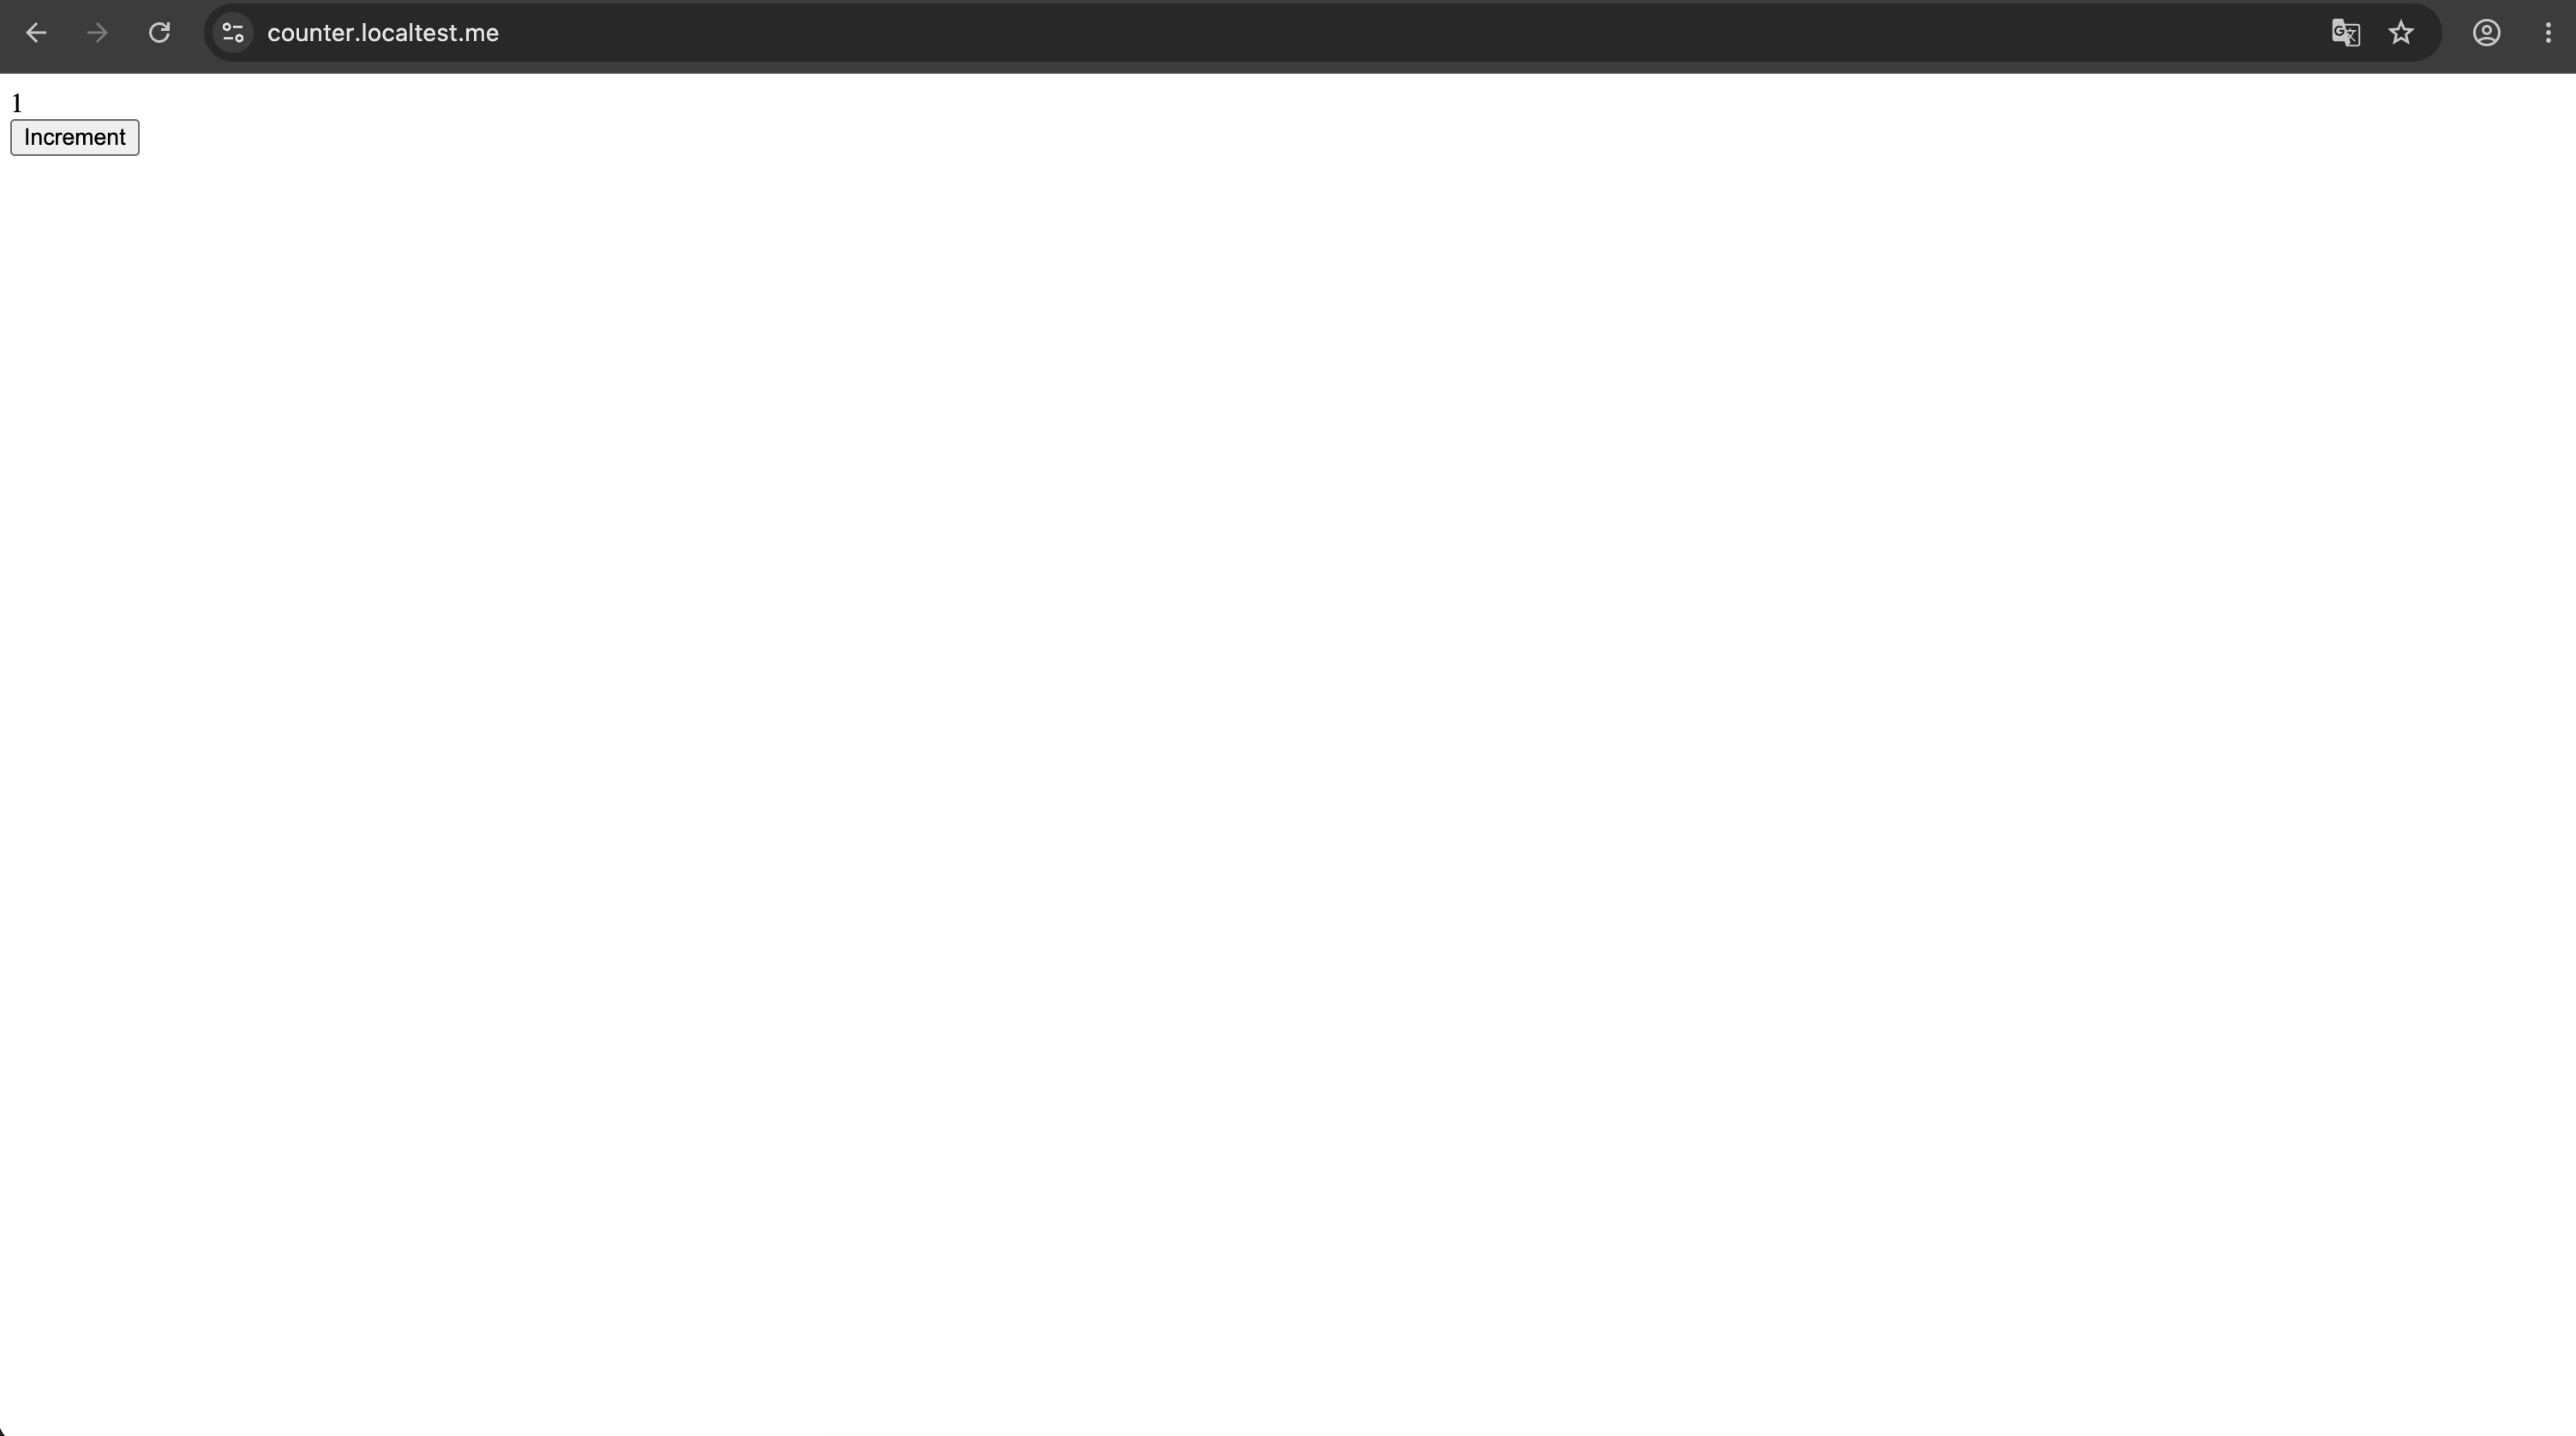

#### доступность бекенда 1.2

In [7]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl get svc -o wide
kubectl describe ingress counter
curl -sS --cacert certs/tls.crt https://counter.localtest.me/api/counter; echo
docker ps
EOF

NAME               TYPE        CLUSTER-IP     EXTERNAL-IP   PORT(S)   AGE   SELECTOR
counter-backend    ClusterIP   10.96.11.211   <none>        80/TCP    18m   app=counter-backend
counter-frontend   ClusterIP   10.96.251.83   <none>        80/TCP    18m   app=counter-frontend
Name:             counter
Labels:           <none>
Namespace:        counter
Address:          localhost
Ingress Class:    nginx
Default backend:  <default>
TLS:
  counter-tls terminates counter.localtest.me
Rules:
  Host                  Path  Backends
  ----                  ----  --------
  counter.localtest.me  
                        /api   counter-backend:http (10.244.2.3:9090)
                        /      counter-frontend:http (10.244.2.4:8080)
Annotations:            <none>
Events:
  Type    Reason  Age                From                      Message
  ----    ------  ----               ----                      -------
  Normal  Sync    17m (x2 over 18m)  nginx-ingress-controller  Scheduled for sync


#### смена порта без пересборки 1.3

In [15]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl get configmap counter-backend-config -o yaml
kubectl describe endpointslices -l kubernetes.io/service-name=counter-backend
sed -i 's/9090/9091/' k8s/backend.yaml
kubectl diff -f k8s/backend.yaml
kubectl apply -f k8s/backend.yaml
kubectl rollout status deployment/counter-backend
sleep 10
kubectl get deploy counter-backend -o wide
kubectl get pod -l app=counter-backend
kubectl exec deploy/counter-backend -- env | grep ^PORT=
kubectl describe endpointslices -l kubernetes.io/service-name=counter-backend
curl -sS --cacert certs/tls.crt https://counter.localtest.me/api/counter; echo
git checkout k8s/backend.yaml
kubectl apply -f k8s/backend.yaml
kubectl rollout status deployment/counter-backend
EOF

apiVersion: v1
data:
  PORT: "9090"
kind: ConfigMap
metadata:
  annotations:
    kubectl.kubernetes.io/last-applied-configuration: |
      {"apiVersion":"v1","data":{"PORT":"9090"},"kind":"ConfigMap","metadata":{"annotations":{},"name":"counter-backend-config","namespace":"counter"}}
  creationTimestamp: "2026-10-21T15:02:30Z"
  name: counter-backend-config
  namespace: counter
  resourceVersion: "45529"
  uid: 88a9a702-0113-46cf-9a54-f8c4453b19fd
Name:         counter-backend-5bh69
Namespace:    counter
Labels:       endpointslice.kubernetes.io/managed-by=endpointslice-controller.k8s.io
              kubernetes.io/service-name=counter-backend
Annotations:  endpoints.kubernetes.io/last-change-trigger-time: 2026-10-21T15:28:13Z
AddressType:  IPv4
Ports:
  Name  Port  Protocol
  ----  ----  --------
  http  9090  TCP
Endpoints:
  - Addresses:  10.244.2.5
    Conditions:
      Ready:    true
    Hostname:   <unset>
    TargetRef:  Pod/counter-backend-d7d7db7d9-26nkq
    NodeName:   course

Updated 1 path from the index


configmap/counter-backend-config configured
deployment.apps/counter-backend configured
service/counter-backend unchanged
Waiting for deployment "counter-backend" rollout to finish: 1 old replicas are pending termination...
Waiting for deployment "counter-backend" rollout to finish: 1 old replicas are pending termination...
deployment "counter-backend" successfully rolled out


#### Вопрос 2. Вы поменяли конфигурацию приложения в кластере. Когда работающие экземпляры увидят изменения и от чего это зависит?

Зависит от того, как конфигурация попадает в контейнер:
- переменные окружения (у нас `PORT` через `envFrom`) читаются только при старте контейнера, поэтому изменения видны только после перезапуска подов — `kubectl rollout restart` или изменение шаблона Deployment, как в 1.3, где поменялся `containerPort`;
- ConfigMap, смонтированный томом без `subPath`, обновится в поде примерно за минуту, но приложение должно само перечитать файл;
- файл, смонтированный через `subPath`, не обновляется вообще.

#### Масштабирование до 3 экземпляров и "зависание" пода 1.4

In [9]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl scale deployment/counter-backend --replicas=3
kubectl rollout status deployment/counter-backend
kubectl get pod -l app=counter-backend -o wide
for i in 1 2 3 4 5 6; do curl -sS --cacert certs/tls.crt -X POST https://counter.localtest.me/api/counter; echo; done
POD=$(kubectl get pod -l app=counter-backend -o jsonpath='{.items[0].metadata.name}')
NODE=$(kubectl get pod $POD -o jsonpath='{.spec.nodeName}')
CID=$(kubectl get pod $POD -o jsonpath='{.status.containerStatuses[0].containerID}' | cut -d/ -f3)
echo "freeze $POD on $NODE"
docker exec $NODE ctr -n k8s.io task kill --signal SIGSTOP $CID
sleep 15
kubectl get pod -l app=counter-backend
kubectl describe endpointslices -l kubernetes.io/service-name=counter-backend
for i in 1 2 3 4 5 6; do curl -sS --cacert certs/tls.crt https://counter.localtest.me/api/counter; echo; done
kubectl logs -l app=counter-backend --prefix --since=15s --tail=30
sleep 75
kubectl get pod -l app=counter-backend
kubectl describe pod $POD
kubectl scale deployment/counter-backend --replicas=1
EOF

deployment.apps/counter-backend scaled
Waiting for deployment "counter-backend" rollout to finish: 1 of 3 updated replicas are available...
Waiting for deployment "counter-backend" rollout to finish: 2 of 3 updated replicas are available...
deployment "counter-backend" successfully rolled out
NAME                              READY   STATUS    RESTARTS   AGE    IP           NODE             NOMINATED NODE   READINESS GATES
counter-backend-d7d7db7d9-26nkq   1/1     Running   0          6s     10.244.2.5   course-worker    <none>           <none>
counter-backend-d7d7db7d9-vxptk   1/1     Running   0          5m3s   10.244.1.5   course-worker2   <none>           <none>
counter-backend-d7d7db7d9-zms5g   1/1     Running   0          6s     10.244.1.6   course-worker2   <none>           <none>
{"count": 1}
{"count": 2}
{"count": 3}
{"count": 4}
{"count": 5}
{"count": 6}
freeze counter-backend-d7d7db7d9-26nkq on course-worker
NAME                              READY   STATUS    RESTARTS   AGE


Я заморозила один под сигналом SIGSTOP, как будто он завис. Readiness-проба перестала проходить, под стал `0/1`, а в EndpointSlice у него `Ready: false`. При этом все 6 запросов прошли, и в логах запросы от curl видны только у двух живых подов, то есть на зависший трафик не шёл. Потом не прошла liveness-проба, и Kubernetes сам перезапустил контейнер: `RESTARTS 1` и событие `Killing`.

#### Вопрос 1. Масштабируйте backend до трёх экземпляров и несколько раз увеличьте счётчик. Что вы видите и почему? Что нужно изменить в приложении, чтобы его можно было масштабировать?

Сразу после масштабирования все 6 POST-запросов попали на старый под (ответы 1–6): новые поды ещё не успели попасть в балансировку ingress. А следующие GET-запросы вернули то 6, то 0: ответы приходят от разных подов, и у каждого свой счётчик - у старого 6, у нового 0.
Так получается, потому что счётчик хранится в памяти каждого процесса. Чтобы приложение можно было масштабировать, счётчик нужно хранить не в памяти, а в общем месте, например в PostgreSQL. Тогда все экземпляры будут показывать одно значение.

#### Ресурсы и QoS 1.5

In [12]:
%%bash
ssh -T devopshw << 'EOF'
kubectl get pod -o custom-columns=NAME:.metadata.name,QOS:.status.qosClass
kubectl describe deploy counter-backend counter-frontend
kubectl describe limitrange defaults
kubectl run lr-test --image=nginx:1.28 --restart=Never
kubectl describe pod lr-test
kubectl delete pod lr-test
kubectl describe node course-worker
EOF

NAME                                QOS
counter-backend-d7d7db7d9-26nkq     Burstable
counter-frontend-79f7678d84-9xhlb   Burstable
Name:                   counter-backend
Namespace:              counter
CreationTimestamp:      Wed, 21 Oct 2026 15:02:30 +0000
Labels:                 <none>
Annotations:            deployment.kubernetes.io/revision: 3
                        kubernetes.io/change-cause: backend 1.0.0
Selector:               app=counter-backend
Replicas:               1 desired | 1 updated | 1 total | 1 available | 0 unavailable
StrategyType:           RollingUpdate
MinReadySeconds:        0
RollingUpdateStrategy:  0 max unavailable, 1 max surge
Pod Template:
  Labels:  app=counter-backend
  Containers:
   backend:
    Image:      counter-backend:1.0.0
    Port:       9090/TCP (http)
    Host Port:  0/TCP (http)
    Limits:
      memory:  128Mi
    Requests:
      cpu:      50m
      memory:   64Mi
    Liveness:   http-get http://:http/api/counter delay=0s timeout=1s perio

#### Вопрос 3. Какой класс QoS получили ваши поды и почему вы выбрали именно такие ресурсы?

Поды получили класс `Burstable`, потому что requests и limits у них разные: requests заданы для CPU и памяти, а limit только для памяти.
Лимит памяти нужен, чтобы контейнер не съел всю память ноды: если он превысит лимит, убьют только его. Лимит CPU я не ставила, потому что в лекции советуют его не ставить: при нехватке CPU приложение не падает, а просто тормозит, а request и так гарантирует ему свою часть процессора. Значения взяла небольшие, с запасом: backend — 64Mi / 128Mi, frontend (он тяжелее) — 128Mi / 256Mi.

#### Выкатка без простоя, сломанная версия, откат 1.6

In [14]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl rollout history deployment/counter-frontend
kubectl set image deployment/counter-frontend frontend=counter-frontend:1.1.0
kubectl annotate deployment/counter-frontend kubernetes.io/change-cause="frontend 1.1.0: новая версия" --overwrite
for i in $(seq 1 30); do curl -s -o /dev/null -w '%{http_code}\n' --cacert certs/tls.crt https://counter.localtest.me/; sleep 1; done
kubectl rollout status deployment/counter-frontend
kubectl get rs -l app=counter-frontend
kubectl set image deployment/counter-frontend frontend=counter-frontend:9.99
kubectl annotate deployment/counter-frontend kubernetes.io/change-cause="frontend 9.99: заведомо сломанный тег" --overwrite
kubectl rollout status deployment/counter-frontend --timeout=30s
kubectl get pod -l app=counter-frontend
for i in 1 2 3 4 5; do curl -s -o /dev/null -w '%{http_code}\n' --cacert certs/tls.crt https://counter.localtest.me/; done
kubectl rollout history deployment/counter-frontend
kubectl rollout undo deployment/counter-frontend
kubectl rollout status deployment/counter-frontend
kubectl get pod -l app=counter-frontend
kubectl rollout history deployment/counter-frontend
EOF

deployment.apps/counter-frontend 
REVISION  CHANGE-CAUSE
1         frontend 1.0.0

deployment.apps/counter-frontend image updated
deployment.apps/counter-frontend annotated
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
deployment "counter-frontend" successfully rolled out
NAME                          DESIRED   CURRENT   READY   AGE
counter-frontend-79f7678d84   0         0         0       69m
counter-frontend-7b5b9b6447   1         1         1       32s
deployment.apps/counter-frontend image updated
deployment.apps/counter-frontend annotated
Waiting for deployment "counter-frontend" rollout to finish: 1 old replicas are pending termination...


error: timed out waiting for the condition


NAME                                READY   STATUS         RESTARTS   AGE
counter-frontend-7b5b9b6447-vtg6z   1/1     Running        0          62s
counter-frontend-7f8d6c79fd-4zm7h   0/1     ErrImagePull   0          30s
200
200
200
200
200
deployment.apps/counter-frontend 
REVISION  CHANGE-CAUSE
1         frontend 1.0.0
2         frontend 1.1.0: новая версия
3         frontend 9.99: заведомо сломанный тег



deployment.apps/counter-frontend rolled back
deployment "counter-frontend" successfully rolled out
NAME                                READY   STATUS        RESTARTS   AGE
counter-frontend-7b5b9b6447-vtg6z   1/1     Running       0          63s
counter-frontend-7f8d6c79fd-4zm7h   0/1     Terminating   0          31s
deployment.apps/counter-frontend 
REVISION  CHANGE-CAUSE
1         frontend 1.0.0
3         frontend 9.99: заведомо сломанный тег
4         frontend 1.1.0: новая версия



Пока выкатывалась версия 1.1.0, все 30 запросов вернули 200, то есть сайт не падал. Потом я выкатила несуществующий тег 9.99: новый под не смог скачать образ (`ErrImagePull`), но старый продолжил работать, все 5 запросов вернули 200. Откатила на 1.1.0 через `rollout undo`. В `rollout history` видно все версии и почему их меняли.

## Задание 2. База данных

#### Решения

- **StatefulSet** — у каждого пода стабильное имя (`counter-db-0`) и свой том, который переживает удаление пода и самого StatefulSet.
- **Headless Service** (`clusterIP: None`) — даёт поду постоянное DNS-имя `counter-db-0.counter-db`, по которому к нему подключаются другие поды.
- **Том через `volumeClaimTemplates`** — PVC создаётся автоматически, в kind его обслуживает StorageClass `standard` (local-path).
- **Таблица** создаётся скриптом `init.sql` из ConfigMap: образ postgres выполняет его при первом запуске.
- **Пароль** генерируется `openssl rand` при создании Secret и не хранится ни в репозитории, ни в манифестах — манифест только ссылается на Secret.

#### 2.3 Развёртывание: случайный пароль и автоматическое создание таблицы

In [17]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl create secret generic counter-db --from-literal=password=$(openssl rand -hex 16)
kubectl describe secret counter-db
grep -rn password k8s/
kubectl apply -f k8s/db.yaml
kubectl rollout status statefulset/counter-db
kubectl get statefulset,pod,svc,pvc
kubectl logs counter-db-0 | grep initdb
kubectl exec counter-db-0 -- psql -U counter -d counter -c '\dt'
kubectl exec counter-db-0 -- psql -U counter -d counter -c 'SELECT * FROM counter'
EOF

secret/counter-db created
Name:         counter-db
Namespace:    counter
Labels:       <none>
Annotations:  <none>

Type:  Opaque

Data
====
password:  32 bytes
k8s/db.yaml:52:                  key: password
configmap/counter-db-init created
service/counter-db created
statefulset.apps/counter-db created
Waiting for 1 pods to be ready...
partitioned roll out complete: 1 new pods have been updated...
NAME                          READY   AGE
statefulset.apps/counter-db   1/1     22s

NAME                                    READY   STATUS    RESTARTS   AGE
pod/counter-backend-d7d7db7d9-2bq56     1/1     Running   0          41m
pod/counter-db-0                        1/1     Running   0          22s
pod/counter-frontend-7b5b9b6447-vtg6z   1/1     Running   0          51m

NAME                       TYPE        CLUSTER-IP     EXTERNAL-IP   PORT(S)    AGE
service/counter-backend    ClusterIP   10.96.11.211   <none>        80/TCP     120m
service/counter-db         ClusterIP   None          

#### 2.2 Подключение подов к БД

In [25]:
%%bash
ssh -T devopshw << 'EOF'
kubectl get svc counter-db
kubectl get pod counter-db-0 -o wide
kubectl run dns-test --image=busybox:1.37 --restart=Never --rm -i -- nslookup counter-db-0.counter-db.counter.svc.cluster.local
EOF

NAME         TYPE        CLUSTER-IP   EXTERNAL-IP   PORT(S)    AGE
counter-db   ClusterIP   None         <none>        5432/TCP   29m
NAME           READY   STATUS    RESTARTS   AGE   IP            NODE            NOMINATED NODE   READINESS GATES
counter-db-0   1/1     Running   0          12m   10.244.2.11   course-worker   <none>           <none>
Server:		10.96.0.10
Address:	10.96.0.10:53

Name:	counter-db-0.counter-db.counter.svc.cluster.local
Address: 10.244.2.11




All commands and output from this session will be recorded in container logs, including credentials and sensitive information passed through the command prompt.
If you don't see a command prompt, try pressing enter.


pod "dns-test" deleted from counter namespace


In [26]:
%%bash
ssh -T devopshw << 'EOF'
kubectl get pod counter-db-0 -o wide
kubectl run psql-client --image=postgres:17 --restart=Never --rm -i --env="PGPASSWORD=$(kubectl get secret counter-db -o jsonpath='{.data.password}' | base64 -d)" -- sh -c "hostname; getent hosts counter-db-0.counter-db; psql -h counter-db-0.counter-db -U counter -d counter -c 'SELECT inet_client_addr() AS client_ip, inet_server_addr() AS db_ip, * FROM counter'"
EOF

NAME           READY   STATUS    RESTARTS   AGE   IP            NODE            NOMINATED NODE   READINESS GATES
counter-db-0   1/1     Running   0          12m   10.244.2.11   course-worker   <none>           <none>
psql-client
10.244.2.11     counter-db-0.counter-db.counter.svc.cluster.local


All commands and output from this session will be recorded in container logs, including credentials and sensitive information passed through the command prompt.
If you don't see a command prompt, try pressing enter.


  client_ip  |    db_ip    | id | count 
-------------+-------------+----+-------
 10.244.1.15 | 10.244.2.11 |  1 |    42
(1 row)

pod "psql-client" deleted from counter namespace


#### 2.1 Сохранение данных при удалении пода

In [20]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl exec counter-db-0 -- psql -U counter -d counter -c 'UPDATE counter SET count = 42 WHERE id = 1'
kubectl get pod counter-db-0 -o wide
kubectl delete pod counter-db-0
sleep 5
kubectl wait --for=condition=ready pod/counter-db-0 --timeout=120s
kubectl get pod counter-db-0 -o wide
kubectl exec counter-db-0 -- psql -U counter -d counter -c 'SELECT * FROM counter'
kubectl delete statefulset counter-db
sleep 10
kubectl get statefulset,pod,pvc
kubectl apply -f k8s/db.yaml
kubectl rollout status statefulset/counter-db
kubectl exec counter-db-0 -- psql -U counter -d counter -c 'SELECT * FROM counter'
EOF

UPDATE 1
NAME           READY   STATUS    RESTARTS   AGE   IP           NODE            NOMINATED NODE   READINESS GATES
counter-db-0   1/1     Running   0          16m   10.244.2.9   course-worker   <none>           <none>
pod "counter-db-0" deleted from counter namespace
pod/counter-db-0 condition met
NAME           READY   STATUS    RESTARTS   AGE   IP            NODE            NOMINATED NODE   READINESS GATES
counter-db-0   1/1     Running   0          6s    10.244.2.10   course-worker   <none>           <none>
 id | count 
----+-------
  1 |    42
(1 row)

statefulset.apps "counter-db" deleted from counter namespace
NAME                                    READY   STATUS    RESTARTS   AGE
pod/counter-backend-d7d7db7d9-2bq56     1/1     Running   0          58m
pod/counter-frontend-7b5b9b6447-vtg6z   1/1     Running   0          68m

NAME                                      STATUS   VOLUME                                     CAPACITY   ACCESS MODES   STORAGECLASS   VOLUMEATTRIBUTE

#### Вопрос 1. Почему вы выбрали именно этот способ запуска БД в Kubernetes?

StatefulSet сделан как раз для приложений с состоянием: у пода стабильное имя `counter-db-0` и свой PVC из `volumeClaimTemplates`, который не удаляется вместе с подом. У Deployment имена подов случайные, и нет отдельного тома на каждый под.

#### Вопрос 2. Где физически лежат данные БД? Что с ними станет, если удалить namespace целиком?

PVC обслуживает StorageClass `standard` (local-path-provisioner в kind): это обычная папка `/var/local-path-provisioner/pvc-…` на ноде, где работает под, то есть внутри Docker-контейнера ноды kind на диске VPS.
Если удалить namespace, вместе с ним удалится PVC. У PV `Reclaim Policy: Delete`, поэтому удалится и PV, и папка с данными — данные пропадут.

In [21]:
%%bash
ssh -T devopshw << 'EOF'
kubectl get storageclass
kubectl get pvc,pv
kubectl describe pv
NODE=$(kubectl get pod counter-db-0 -o jsonpath='{.spec.nodeName}')
docker exec $NODE ls -la /var/local-path-provisioner
EOF

NAME                 PROVISIONER             RECLAIMPOLICY   VOLUMEBINDINGMODE      ALLOWVOLUMEEXPANSION   AGE
standard (default)   rancher.io/local-path   Delete          WaitForFirstConsumer   false                  9h
NAME                                      STATUS   VOLUME                                     CAPACITY   ACCESS MODES   STORAGECLASS   VOLUMEATTRIBUTESCLASS   AGE
persistentvolumeclaim/data-counter-db-0   Bound    pvc-ee5f4249-6457-4ba2-a774-402ee0cc56b1   1Gi        RWO            standard       <unset>                 23m

NAME                                                        CAPACITY   ACCESS MODES   RECLAIM POLICY   STATUS   CLAIM                       STORAGECLASS   VOLUMEATTRIBUTESCLASS   REASON   AGE
persistentvolume/pvc-ee5f4249-6457-4ba2-a774-402ee0cc56b1   1Gi        RWO            Delete           Bound    counter/data-counter-db-0   standard       <unset>                          23m
Name:              pvc-ee5f4249-6457-4ba2-a774-402ee0cc56b1
Labels: 

## Задание 3. Эксплуатация

#### Решения

- **node-exporter в DaemonSet** — DaemonSet держит один под на каждой ноде и сам добавляет под на новую ноду.
- **Toleration на control-plane** — без неё под не встанет на control-plane: на ноде taint `NoSchedule`.
- **hostNetwork и hostPath /proc, /sys (только чтение)** — чтобы агент видел метрики самой ноды, а не своего контейнера.
- **Маленькие ресурсы** — 10m CPU и 24Mi памяти, лимит 64Mi: node-exporter лёгкий, этого хватает.
- **CronJob с `timeZone: Europe/Moscow`** — расписание в московском времени, отдельно на 9:00 (3 реплики) и на 18:00 (1 реплика).

#### 3.1 Метрики нод

In [2]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl apply -f k8s/node-exporter.yaml
kubectl rollout status daemonset/node-exporter -n monitoring
kubectl get nodes
kubectl get daemonset -n monitoring
kubectl get pod -n monitoring -o wide
for p in $(kubectl get pod -n monitoring -o name); do kubectl exec -n monitoring $p -- wget -qO- localhost:9100/metrics | grep node_uname_info; done
kubectl describe daemonset node-exporter -n monitoring
docker exec course-control-plane crictl stats
EOF

namespace/monitoring created
daemonset.apps/node-exporter created
Waiting for daemon set "node-exporter" rollout to finish: 0 of 3 updated pods are available...
Waiting for daemon set "node-exporter" rollout to finish: 1 of 3 updated pods are available...
Waiting for daemon set "node-exporter" rollout to finish: 2 of 3 updated pods are available...
daemon set "node-exporter" successfully rolled out
NAME                   STATUS   ROLES           AGE   VERSION
course-control-plane   Ready    control-plane   46h   v1.37.0
course-worker          Ready    <none>          46h   v1.37.0
course-worker2         Ready    <none>          46h   v1.37.0
NAME            DESIRED   CURRENT   READY   UP-TO-DATE   AVAILABLE   NODE SELECTOR   AGE
node-exporter   3         3         3       3            3           <none>          6s
NAME                  READY   STATUS    RESTARTS   AGE   IP           NODE                   NOMINATED NODE   READINESS GATES
node-exporter-2vxf8   1/1     Running   0      

#### 3.1.1 Новая нода получает агента автоматически

In [5]:
%%bash
ssh -T devopshw << 'EOF'
kubectl get daemonset -n monitoring
kubectl get pod -n monitoring -o wide
docker stop course-worker2
kubectl delete node course-worker2
sleep 60
kubectl get nodes
kubectl get daemonset -n monitoring
kubectl get pod -n monitoring -o wide
docker start course-worker2
sleep 30
kubectl wait --for=condition=ready node/course-worker2 --timeout=180s
kubectl rollout status daemonset/node-exporter -n monitoring
kubectl get nodes
kubectl get daemonset -n monitoring
kubectl get pod -n monitoring -o wide
EOF

NAME            DESIRED   CURRENT   READY   UP-TO-DATE   AVAILABLE   NODE SELECTOR   AGE
node-exporter   3         3         3       3            3           <none>          9m32s
NAME                  READY   STATUS    RESTARTS       AGE     IP           NODE                   NOMINATED NODE   READINESS GATES
node-exporter-2vxf8   1/1     Running   1 (8m5s ago)   9m32s   172.19.0.3   course-worker2         <none>           <none>
node-exporter-fhm99   1/1     Running   0              9m32s   172.19.0.4   course-control-plane   <none>           <none>
node-exporter-vwwcr   1/1     Running   0              9m32s   172.19.0.2   course-worker          <none>           <none>
course-worker2
node "course-worker2" deleted
NAME                   STATUS   ROLES           AGE   VERSION
course-control-plane   Ready    control-plane   46h   v1.37.0
course-worker          Ready    <none>          46h   v1.37.0
NAME            DESIRED   CURRENT   READY   UP-TO-DATE   AVAILABLE   NODE SELECTOR   AGE

#### 3.2 Скейл по расписанию

In [4]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl apply -f k8s/frontend-scaler.yaml
kubectl get cronjob
kubectl describe role frontend-scaler
kubectl auth can-i get deployments/counter-frontend --as=system:serviceaccount:counter:frontend-scaler
kubectl auth can-i patch deployments/counter-frontend --subresource=scale --as=system:serviceaccount:counter:frontend-scaler
kubectl auth can-i patch deployments/counter-backend --subresource=scale --as=system:serviceaccount:counter:frontend-scaler
kubectl auth can-i delete deployments/counter-frontend --as=system:serviceaccount:counter:frontend-scaler
kubectl auth can-i create pods --as=system:serviceaccount:counter:frontend-scaler
kubectl auth can-i get secrets --as=system:serviceaccount:counter:frontend-scaler
kubectl get deploy counter-frontend
kubectl create job frontend-scale-up-manual --from=cronjob/frontend-scale-up
kubectl wait --for=condition=complete job/frontend-scale-up-manual --timeout=120s
kubectl logs job/frontend-scale-up-manual
kubectl get deploy counter-frontend
kubectl create job frontend-scale-down-manual --from=cronjob/frontend-scale-down
kubectl wait --for=condition=complete job/frontend-scale-down-manual --timeout=120s
kubectl logs job/frontend-scale-down-manual
kubectl get deploy counter-frontend
EOF

serviceaccount/frontend-scaler created
role.rbac.authorization.k8s.io/frontend-scaler created
rolebinding.rbac.authorization.k8s.io/frontend-scaler created
cronjob.batch/frontend-scale-up created
cronjob.batch/frontend-scale-down created
NAME                  SCHEDULE     TIMEZONE        SUSPEND   ACTIVE   LAST SCHEDULE   AGE
frontend-scale-down   0 18 * * *   Europe/Moscow   False     0        <none>          0s
frontend-scale-up     0 9 * * *    Europe/Moscow   False     0        <none>          0s
Name:         frontend-scaler
Labels:       <none>
Annotations:  <none>
PolicyRule:
  Resources               Non-Resource URLs  Resource Names      Verbs
  ---------               -----------------  --------------      -----
  deployments.apps/scale  []                 [counter-frontend]  [get update patch]
  deployments.apps        []                 [counter-frontend]  [get]
yes
yes
no
no
no
no
NAME               READY   UP-TO-DATE   AVAILABLE   AGE
counter-frontend   1/1     1         

## Задание 4. Поставка через Helm

#### 4.1 Установка

In [9]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
helm version
helm install counter-dev helm/counter -n dev --create-namespace --set ingress.host=counter-dev.localtest.me --set-file tls.crt=certs/tls.crt --set-file tls.key=certs/tls.key --wait
helm install counter-prod helm/counter -n prod --create-namespace --set ingress.host=counter-prod.localtest.me --set-file tls.crt=certs/tls.crt --set-file tls.key=certs/tls.key --wait
helm list -A
kubectl get all,ingress -n dev
kubectl get all,ingress -n prod
EOF

version.BuildInfo{Version:"v3.22.1", GitCommit:"d6c1a0e4027caa6abc7892e7ea9f0cda7447baa3", GitTreeState:"clean", GoVersion:"go1.26.9"}
NAME: counter-dev
LAST DEPLOYED: Fri Oct 23 08:00:57 2026
NAMESPACE: dev
STATUS: deployed
REVISION: 1
TEST SUITE: None
NAME: counter-prod
LAST DEPLOYED: Fri Oct 23 08:01:13 2026
NAMESPACE: prod
STATUS: deployed
REVISION: 1
TEST SUITE: None
NAME        	NAMESPACE	REVISION	UPDATED                                	STATUS  	CHART        	APP VERSION
counter-dev 	dev      	1       	2026-10-23 08:00:57.310960395 +0000 UTC	deployed	counter-0.1.0	1.1.0      
counter-prod	prod     	1       	2026-10-23 08:01:13.312243298 +0000 UTC	deployed	counter-0.1.0	1.1.0      
NAME                                        READY   STATUS      RESTARTS   AGE
pod/counter-dev-backend-786f745747-4cf9q    1/1     Running     0          31s
pod/counter-dev-check-q8k9f                 0/1     Completed   0          22s
pod/counter-dev-frontend-85ffd6b689-4ht5v   1/1     Running     0  

In [11]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
curl --cacert certs/tls.crt https://counter-dev.localtest.me/api/counter
echo
curl --cacert certs/tls.crt -X POST https://counter-dev.localtest.me/api/counter
echo
curl --cacert certs/tls.crt -X POST https://counter-dev.localtest.me/api/counter
echo
curl --cacert certs/tls.crt https://counter-prod.localtest.me/api/counter
echo
curl --cacert certs/tls.crt -I https://counter-prod.localtest.me/
EOF

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed
100     12 100     12   0      0     42      0                              0


{"count": 0}


  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed


{"count": 1}


100     12 100     12   0      0    986      0                              0
  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed


...

100     12 100     12   0      0    847      0                              0
  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed


{"count": 0}


100     12 100     12   0      0     89      0                              0
  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed


HTTP/2 200 
date: Fri, 23 Oct 2026 08:03:32 GMT
content-type: text/html; charset=utf-8
content-length: 4887
vary: rsc, next-router-state-tree, next-router-prefetch, next-router-segment-prefetch, Accept-Encoding
x-nextjs-cache: HIT
x-nextjs-prerender: 1
x-nextjs-prerender: 1
x-nextjs-stale-time: 300
x-powered-by: Next.js
cache-control: s-maxage=31536000
etag: "gmsff428xl3rr"
strict-transport-security: max-age=31536000; includeSubDomains



  0   4887   0      0   0      0      0      0                              0


#### 4.2 Перезапуск, автоматическая проверка, логи


In [12]:
%%bash
ssh -T devopshw << 'EOF'
kubectl get jobs -n dev
kubectl logs -n dev job/counter-dev-check
kubectl get jobs -n prod
kubectl logs -n prod job/counter-prod-check
EOF

NAME                STATUS     COMPLETIONS   DURATION   AGE
counter-dev-check   Complete   1/1           7s         3m27s
{"count": 0}NAME                 STATUS     COMPLETIONS   DURATION   AGE
counter-prod-check   Complete   1/1           6s         3m11s
{"count": 0}

In [13]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl get pods -n dev
kubectl get pods -n dev -l app=counter-dev-backend -o jsonpath='{.items[*].metadata.annotations}'
echo
helm upgrade counter-dev helm/counter -n dev --reuse-values --set backend.port=9091 --description "backend port 9090 -> 9091" --wait
kubectl get pods -n dev
kubectl get pods -n dev -l app=counter-dev-backend -o jsonpath='{.items[*].metadata.annotations}'
echo
kubectl describe configmap counter-dev-backend -n dev
kubectl logs -n dev job/counter-dev-check
echo
helm history counter-dev -n dev
EOF

NAME                                    READY   STATUS      RESTARTS   AGE
counter-dev-backend-786f745747-4cf9q    1/1     Running     0          4m54s
counter-dev-check-q8k9f                 0/1     Completed   0          4m45s
counter-dev-frontend-85ffd6b689-4ht5v   1/1     Running     0          4m54s
{"checksum/config":"c972a71be8a7432ab587de2cd18d989e9fa898e33c5650fd563c2a648de56ed7"}
Release "counter-dev" has been upgraded. Happy Helming!
NAME: counter-dev
LAST DEPLOYED: Fri Oct 23 08:05:52 2026
NAMESPACE: dev
STATUS: deployed
REVISION: 2
TEST SUITE: None
NAME                                    READY   STATUS        RESTARTS   AGE
counter-dev-backend-5b56d4555c-lqpjj    1/1     Running       0          6s
counter-dev-backend-786f745747-4cf9q    1/1     Terminating   0          5m1s
counter-dev-check-h2gz4                 0/1     Completed     0          4s
counter-dev-frontend-85ffd6b689-4ht5v   1/1     Running       0          5m1s
{"checksum/config":"774ce46bf75756963faa076e6f8

In [14]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
helm rollback counter-dev 1 -n dev --wait
helm history counter-dev -n dev
kubectl describe configmap counter-dev-backend -n dev
kubectl get pods -n dev
curl --cacert certs/tls.crt https://counter-dev.localtest.me/api/counter
echo
EOF

Rollback was a success! Happy Helming!
REVISION	UPDATED                 	STATUS    	CHART        	APP VERSION	DESCRIPTION              
1       	Fri Oct 23 08:00:57 2026	superseded	counter-0.1.0	1.1.0      	Install complete         
2       	Fri Oct 23 08:05:52 2026	superseded	counter-0.1.0	1.1.0      	backend port 9090 -> 9091
3       	Fri Oct 23 08:06:17 2026	deployed  	counter-0.1.0	1.1.0      	Rollback to 1            
Name:         counter-dev-backend
Namespace:    dev
Labels:       app.kubernetes.io/managed-by=Helm
Annotations:  meta.helm.sh/release-name: counter-dev
              meta.helm.sh/release-namespace: dev

Data
====
PORT:
----
9090


BinaryData
====

Events:  <none>
NAME                                    READY   STATUS        RESTARTS   AGE
counter-dev-backend-5b56d4555c-lqpjj    1/1     Terminating   0          35s
counter-dev-backend-786f745747-wtfpk    1/1     Running       0          10s
counter-dev-check-6vt8z                 0/1     Completed     0          4s
c

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed


{"count": 0}


100     12 100     12   0      0    787      0                              0


## Дополнительное задание: база данных в чарте

#### включаем БД параметром

In [16]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
kubectl create secret generic counter-db -n dev --from-literal=password=$(openssl rand -base64 16)
helm upgrade counter-dev helm/counter -n dev --reuse-values --set db.enabled=true --set db.existingSecret=counter-db --description "db enabled" --wait
kubectl get statefulset,pod,pvc -n dev
kubectl exec -n dev counter-dev-db-0 -- psql -U counter -d counter -c "UPDATE counter SET count = 42 WHERE id = 1"
kubectl exec -n dev counter-dev-db-0 -- psql -U counter -d counter -c "SELECT * FROM counter"
kubectl get statefulset,pvc -n prod
EOF

secret/counter-db created
Release "counter-dev" has been upgraded. Happy Helming!
NAME: counter-dev
LAST DEPLOYED: Fri Oct 23 08:07:21 2026
NAMESPACE: dev
STATUS: deployed
REVISION: 4
TEST SUITE: None
NAME                              READY   AGE
statefulset.apps/counter-dev-db   1/1     15s

NAME                                        READY   STATUS      RESTARTS   AGE
pod/counter-dev-backend-786f745747-wtfpk    1/1     Running     0          80s
pod/counter-dev-check-fbsxn                 0/1     Completed   0          3s
pod/counter-dev-db-0                        1/1     Running     0          15s
pod/counter-dev-frontend-85ffd6b689-4ht5v   1/1     Running     0          6m40s

NAME                                          STATUS   VOLUME                                     CAPACITY   ACCESS MODES   STORAGECLASS   VOLUMEATTRIBUTESCLASS   AGE
persistentvolumeclaim/data-counter-dev-db-0   Bound    pvc-294a70e4-6356-477e-a10e-a82073d07b07   1Gi        RWO            standard       <un

No resources found in prod namespace.


#### удаляем релиз и ставим заново

In [17]:
%%bash
ssh -T devopshw << 'EOF'
cd ~/projects/hw4_work
helm uninstall counter-dev -n dev
helm list -n dev
kubectl get pvc,secret -n dev
helm install counter-dev helm/counter -n dev --set ingress.host=counter-dev.localtest.me --set-file tls.crt=certs/tls.crt --set-file tls.key=certs/tls.key --set db.enabled=true --set db.existingSecret=counter-db --wait
kubectl get pod,pvc -n dev
kubectl exec -n dev counter-dev-db-0 -- psql -U counter -d counter -c "SELECT * FROM counter"
EOF

release "counter-dev" uninstalled
NAME	NAMESPACE	REVISION	UPDATED	STATUS	CHART	APP VERSION
NAME                                          STATUS   VOLUME                                     CAPACITY   ACCESS MODES   STORAGECLASS   VOLUMEATTRIBUTESCLASS   AGE
persistentvolumeclaim/data-counter-dev-db-0   Bound    pvc-294a70e4-6356-477e-a10e-a82073d07b07   1Gi        RWO            standard       <unset>                 2m6s

NAME                TYPE     DATA   AGE
secret/counter-db   Opaque   1      2m7s
NAME: counter-dev
LAST DEPLOYED: Fri Oct 23 08:09:28 2026
NAMESPACE: dev
STATUS: deployed
REVISION: 1
TEST SUITE: None
NAME                                        READY   STATUS      RESTARTS   AGE
pod/counter-dev-backend-786f745747-8dnb2    1/1     Running     0          11s
pod/counter-dev-check-2kpzg                 0/1     Completed   0          3s
pod/counter-dev-db-0                        1/1     Running     0          11s
pod/counter-dev-frontend-85ffd6b689-mx6kb   1/1     Runnin